# Linear Regression with Scikit-Learn
## Moeletsi Mangaliso Namane
## 05 November 2026

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp
import seaborn as sns

import pandas as pd


In [3]:
path = r"G:\My Drive\INTRO TO ML AND DATA SCIENCE\data\Advertising.csv"

df = pd.read_csv(path)
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


### Multiple Features
- The previous study was about total advertising spend and sales as well as predicting the total sales for some value of total spend.
- This one explores what is the relationship between each advertising channel (TV, Radio, Newspaper) and sales?

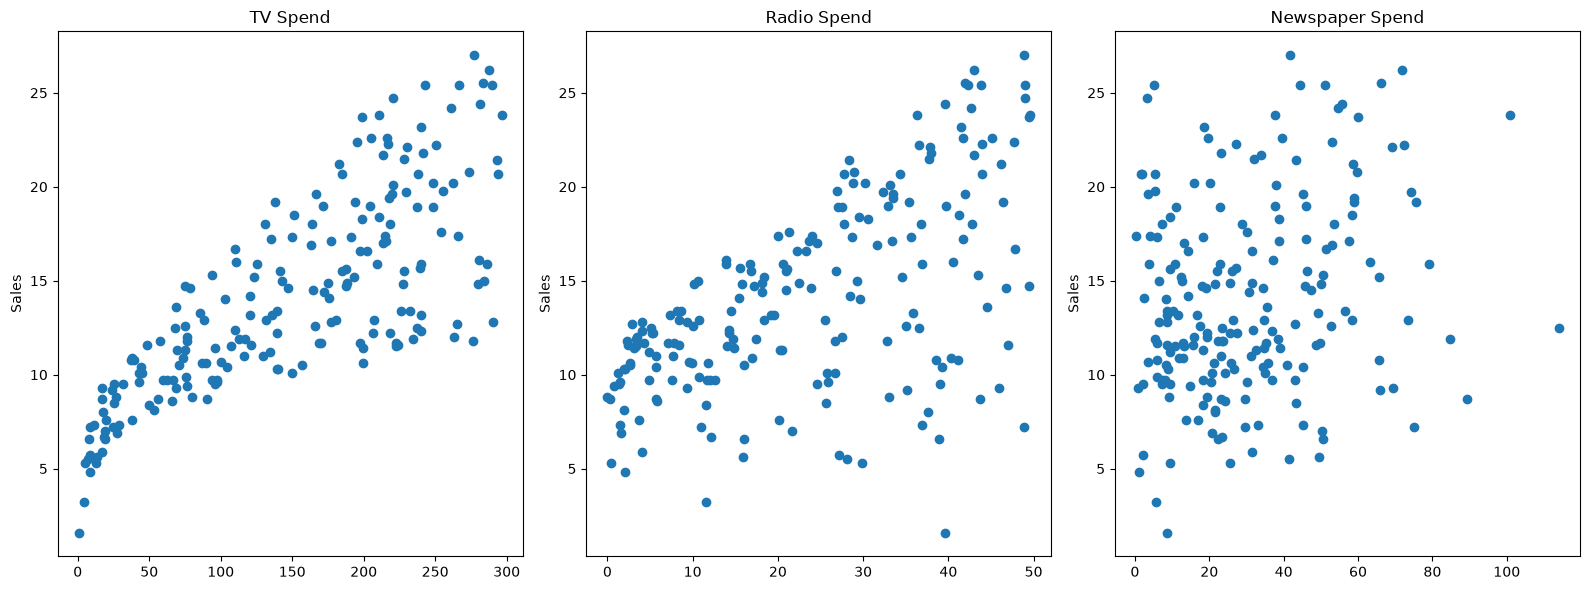

In [4]:
fig,axes = plt.subplots(nrows=1,ncols=3,figsize=(16,6))

# For TV vs Sales
axes[0].plot(df['TV'],df['sales'],'o')
axes[0].set_ylabel("Sales")
axes[0].set_title("TV Spend")

# For radio vs sales
axes[1].plot(df['radio'],df['sales'],'o')
axes[1].set_title("Radio Spend")
axes[1].set_ylabel("Sales")

# For newspaper vs sales
axes[2].plot(df['newspaper'],df['sales'],'o')
axes[2].set_title("Newspaper Spend");
axes[2].set_ylabel("Sales")
plt.tight_layout();

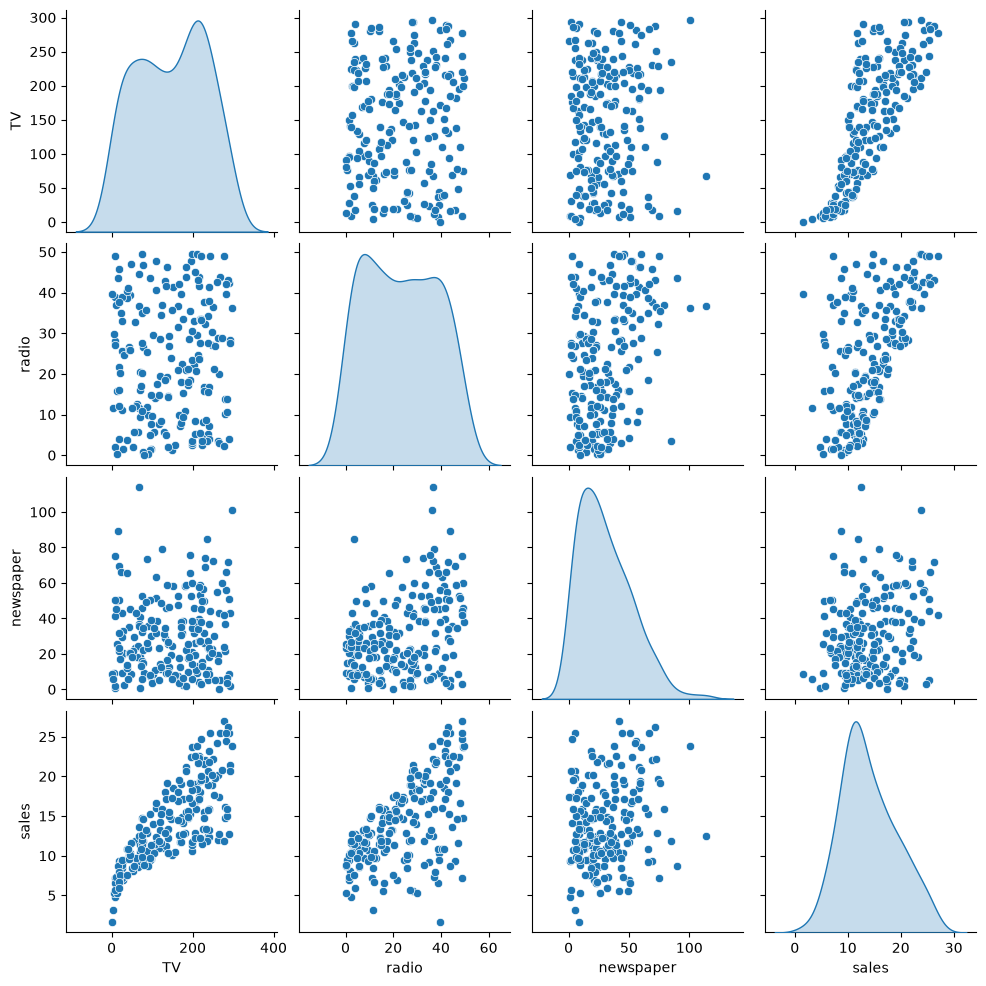

In [5]:
sns.pairplot(df,diag_kind='kde');

## KDE Plot Interpretations

Based on the diagonal plots in the pairplot, here is the interpretation of the distribution for each variable:

- TV: The distribution has two distinct peaks (bimodal), indicating two common spending clusters—a smaller group of low spending (near 0-50) and a larger, more common group of high spending (near 200-250).

- Radio: The distribution is broad and relatively flat across its range (0 to 50), meaning spending amounts are fairly evenly distributed without a single dominant peak.

- Newspaper: The distribution is heavily right-skewed, meaning the vast majority of newspaper budgets are very small (clustered tightly near 0-20), with only a few rare cases of high spending creating the long tail trailing to the right.

- Sales: The distribution is mostly bell-shaped (normal) but slightly right-skewed, with the majority of sales clustering centrally around the 10 to 15 mark and gradually tapering off toward the higher end.

In [6]:
X = df.drop('sales',axis=1)
y = df['sales']

## Train | Test - SPLIT

In [7]:
from sklearn.model_selection import train_test_split

### random state:
In this case the data is being randomized to try and make sure that the predictor can actually predict. [stackoverflow](https://stackoverflow.com/questions/28064634/random-state-pseudo-random-number-in-scikit-learn)

In [8]:
# train_test_split, randomizes the data then splits the test data based on percentage choosen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

## Creating a model

In [9]:
from sklearn.linear_model import LinearRegression

# Creating an instance of the model with a parameter 
model = LinearRegression()

# Fitting the model on the training data
- fit() finds the slope $m$ and intercept $b$ that minimise the sum of squared differences between predicted and actual training values.


In [10]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.04, 0.19,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','radio','newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.152
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [11]:
# Now this is inspecting what the model learned
model.coef_ # The slope one input feature per coeffient
model.intercept_ # The intercept feature
print( model.coef_,"\n",model.intercept_,sep='')

[ 0.04469599  0.1875657  -0.00032275]
3.151526768070651


## Metrics 
### Mean Absolute Error (MAE) 
- This is the size of the error divided by the number of segments

$$\frac 1n\sum_{i=1}^n|y_i-\hat{y}_i|$$

### Mean Squared Error (MSE) 
- This is the average error area. Bigger errors will contribute more because the errors grow quadratically so after 1 errors contribute more than just absolute errors.

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

### RMSE units match so easier to interpret than MSE

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$

In regression we want our models to minimize this loss function

# Next step is to calculate the performance on the Test Set.

In [12]:
# Testing the model on data it has never seen before, the separated test features

# This is what I call y_hat
test_predictions = model.predict(X_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test,test_predictions)
mse = mean_squared_error(y_test,test_predictions)
rmse = np.sqrt(mse)

print(f"The mean absolute error is: {mae}")
print(f"The mean squared error is: {mse}")
print(f"The root mean squared error is: {rmse}")

print("This is checking if the average sales value correlates with the error:",df['sales'].mean())

The mean absolute error is: 1.213745773614481
The mean squared error is: 2.2987166978863782
The root mean squared error is: 1.516151937599388
This is checking if the average sales value correlates with the error: 14.0225


## Residuals
Thinking about [Anscombe's quartet2](https://en.wikipedia.org/wiki/Anscombe%27s_quartet2222222) from From Wikipedia, the free encyclopedia

> Anscombe's quartet comprises four datasets that have nearly identical simple descriptive statistics, yet have very different distributions and appear very different when graphed. Each dataset consists of eleven (x, y) points. They were constructed in 1973 by the statistician Francis Anscombe to demonstrate both the importance of graphing data when analyzing it, and the effect of outliers and other influential observations on statistical properties. He described the article as being intended to counter the impression among statisticians that "numerical calculations are exact, but graphs are rough".[1]

This is a table that illustrates the discriptive statistics of 4 data sets that look different when graphed. These statistic values were obtained from fitting a regresion line, and when you plot the data you realize that for some of them regression is not a good fit.
<table class="wikitable">
<tbody><tr>
<th>Property
</th>
<th>Value
</th>
<th>Accuracy
</th></tr>
<tr>
<td><a href="/wiki/Mean" title="Mean">Mean</a> of <i>x</i>
</td>
<td>9
</td>
<td>exact
</td></tr>
<tr>
<td>Sample <a href="/wiki/Variance" title="Variance">variance</a> of <i>x</i>  :  <span class="mwe-math-element"><span class="mwe-math-mathml-inline mwe-math-mathml-a11y" style="display: none;"><math xmlns="http://www.w3.org/1998/Math/MathML"  alttext="{\displaystyle \sigma ^{2}}">
  <semantics>
    <mrow class="MJX-TeXAtom-ORD">
      <mstyle displaystyle="true" scriptlevel="0">
        <msup>
          <mi>&#x03C3;<!-- σ --></mi>
          <mrow class="MJX-TeXAtom-ORD">
            <mn>2</mn>
          </mrow>
        </msup>
      </mstyle>
    </mrow>
    <annotation encoding="application/x-tex">{\displaystyle \sigma ^{2}}</annotation>
  </semantics>
</math></span><img src="https://wikimedia.org/api/rest_v1/media/math/render/svg/53a5c55e536acf250c1d3e0f754be5692b843ef5" class="mwe-math-fallback-image-inline" aria-hidden="true" style="vertical-align: -0.338ex; width:2.385ex; height:2.676ex;" alt="\sigma ^{2}"/></span>
</td>
<td>11
</td>
<td>exact
</td></tr>
<tr>
<td>Mean of <i>y</i>
</td>
<td>7.50
</td>
<td>to 2 decimal places
</td></tr>
<tr>
<td>Sample variance of <i>y</i>  :  <span class="mwe-math-element"><span class="mwe-math-mathml-inline mwe-math-mathml-a11y" style="display: none;"><math xmlns="http://www.w3.org/1998/Math/MathML"  alttext="{\displaystyle \sigma ^{2}}">
  <semantics>
    <mrow class="MJX-TeXAtom-ORD">
      <mstyle displaystyle="true" scriptlevel="0">
        <msup>
          <mi>&#x03C3;<!-- σ --></mi>
          <mrow class="MJX-TeXAtom-ORD">
            <mn>2</mn>
          </mrow>
        </msup>
      </mstyle>
    </mrow>
    <annotation encoding="application/x-tex">{\displaystyle \sigma ^{2}}</annotation>
  </semantics>
</math></span><img src="https://wikimedia.org/api/rest_v1/media/math/render/svg/53a5c55e536acf250c1d3e0f754be5692b843ef5" class="mwe-math-fallback-image-inline" aria-hidden="true" style="vertical-align: -0.338ex; width:2.385ex; height:2.676ex;" alt="\sigma ^{2}"/></span>
</td>
<td>4.125
</td>
<td>±0.003
</td></tr>
<tr>
<td><a href="/wiki/Correlation" class="mw-redirect" title="Correlation">Correlation</a> between <i>x</i> and <i>y</i>
</td>
<td>0.816
</td>
<td>to 3 decimal places
</td></tr>
<tr>
<td><a href="/wiki/Linear_regression" title="Linear regression">Linear regression</a> line
</td>
<td><i>y</i>&#160;=&#160;3.00&#160;+&#160;0.500<i>x</i>
</td>
<td>to 2 and 3 decimal places, respectively
</td></tr>
<tr>
<td><a href="/wiki/Coefficient_of_determination" title="Coefficient of determination">Coefficient of determination</a> of the linear regression  :  <span class="mwe-math-element"><span class="mwe-math-mathml-inline mwe-math-mathml-a11y" style="display: none;"><math xmlns="http://www.w3.org/1998/Math/MathML"  alttext="{\displaystyle R^{2}}">
  <semantics>
    <mrow class="MJX-TeXAtom-ORD">
      <mstyle displaystyle="true" scriptlevel="0">
        <msup>
          <mi>R</mi>
          <mrow class="MJX-TeXAtom-ORD">
            <mn>2</mn>
          </mrow>
        </msup>
      </mstyle>
    </mrow>
    <annotation encoding="application/x-tex">{\displaystyle R^{2}}</annotation>
  </semantics>
</math></span><img src="https://wikimedia.org/api/rest_v1/media/math/render/svg/5ce07e278be3e058a6303de8359f8b4a4288264a" class="mwe-math-fallback-image-inline" aria-hidden="true" style="vertical-align: -0.338ex; width:2.818ex; height:2.676ex;" alt="R^{2}"/></span>
</td>
<td>0.67
</td>
<td>to 2 decimal places
</td></tr></tbody></table>

In [13]:
quartet = pd.read_csv(r"G:\My Drive\INTRO TO ML AND DATA SCIENCE\data\anscombes_quartet1.csv")
quartet2 = pd.read_csv(r"G:\My Drive\INTRO TO ML AND DATA SCIENCE\data\anscombes_quartet2.csv")
quartet3 = pd.read_csv(r"G:\My Drive\INTRO TO ML AND DATA SCIENCE\data\anscombes_quartet4.csv")
quartet4 = pd.read_csv(r"G:\My Drive\INTRO TO ML AND DATA SCIENCE\data\ascombes_quartet2.csv")

,x,y,y_hat,residual
0,10.0,8.04,8.0,0.04
1,8.0,6.95,7.0,-0.05
2,13.0,7.58,9.5,-1.92
3,9.0,8.81,7.5,1.31
4,11.0,8.33,8.5,-0.17
5,14.0,9.96,10.0,-0.04
6,6.0,7.24,6.0,1.24
7,4.0,4.26,5.0,-0.74
8,12.0,10.84,9.0,1.84
9,7.0,4.82,6.5,-1.68


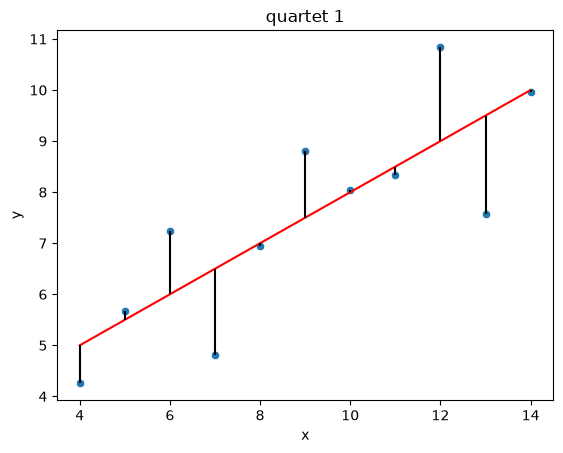

In [14]:
# y_hat = 3.00 + 0.50x
quartet["y_hat"] = 3  + 0.5 * quartet['x']
quartet['residual'] = quartet['y'] - quartet['y_hat']
display(quartet)

sns.scatterplot(data=quartet, x='x',y='y')
sns.lineplot(data=quartet,x='x',y='y_hat',color='red')
plt.vlines(quartet['x'],quartet['y'],quartet['y']-quartet['residual'],colors='black')
plt.title("quartet 1");

## We cannot always plot.
- We are a three dimensional species, if there are N>3 features we cannot plot to see if a regression model is a good fit. So we rely on residual distribution.
 - When you plot the residual errors for the regression method they should be random and close to a Gaussian distribution with a mean of zero.
 - It should be more probable for them to approach a mean of zero, we want the expectation value of the residuals to be zero or close to zero.
 - The residuals should be clustered at zero to give a near perfect fit.

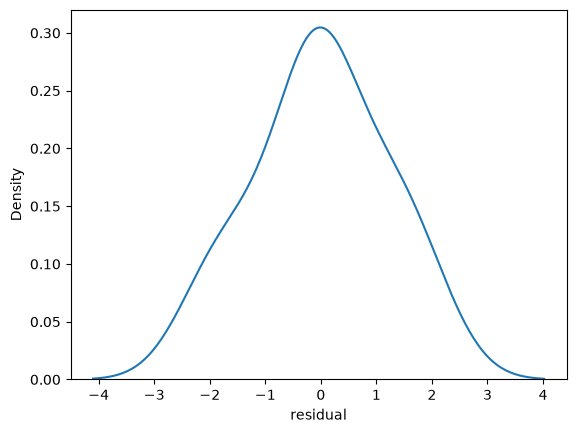

In [15]:
sns.kdeplot(quartet['residual']);

From above we can see that the peak of the residual errors is very close to zero, that is a good sign that linear regression works well for quartet 1. The only way it could get better is if it was narrower.

### The residual plot
- This one requires that the number of datapoints above and below zero error be equal. And the distribution appear random and not be an analytical function. (Why is that?)
- This implies random error.

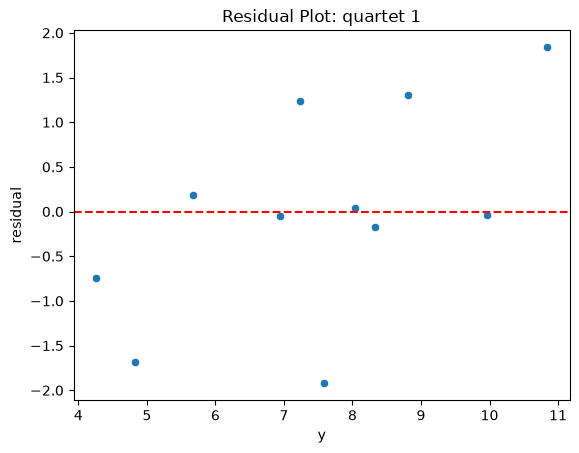

In [16]:
sns.scatterplot(data=quartet,x='y',y='residual')
plt.axhline(y=0, color='r', linestyle='--')
plt.title("Residual Plot: quartet 1");

In [17]:
# quartet2 2

quartet2.columns = ['x','y']

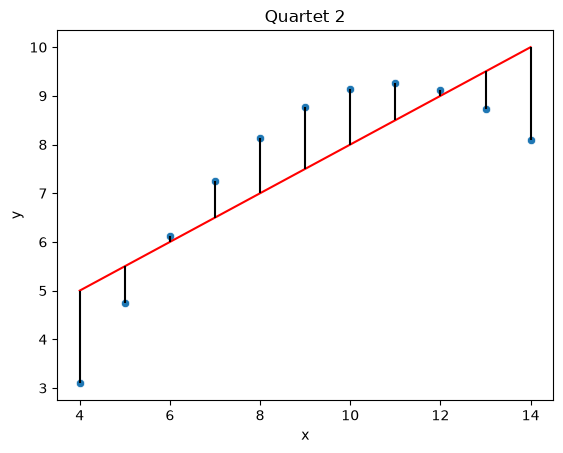

In [18]:

# y = 3.00 + 0.500x
quartet2['pred_y'] = 3 + 0.5 * quartet2['x']
quartet2['residual'] = quartet2['y'] - quartet2['pred_y']

sns.scatterplot(data=quartet2,x='x',y='y')
sns.lineplot(data=quartet2,x='x',y='pred_y',color='red')
plt.vlines(quartet2['x'],quartet2['y'],quartet2['y']-quartet2['residual'],colors="black")
plt.title("Quartet 2");

From the figure it is clear that a higher degree polynomial would fit better. So linear regression is not a good fit and the plot above puts emphasis on this ordeal.

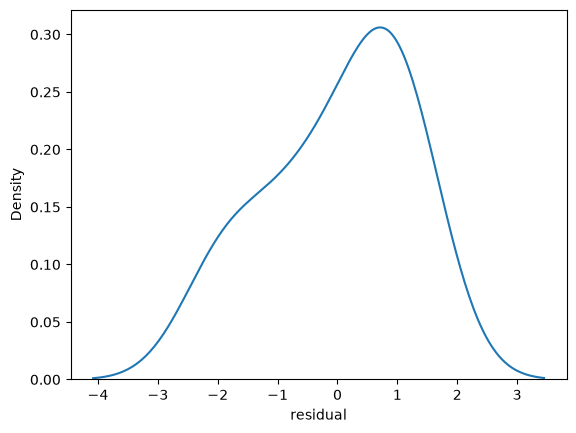

In [19]:
sns.kdeplot(quartet2['residual']);

### Distribution not peaking at zero is indication that linear regression is not a good regression fit

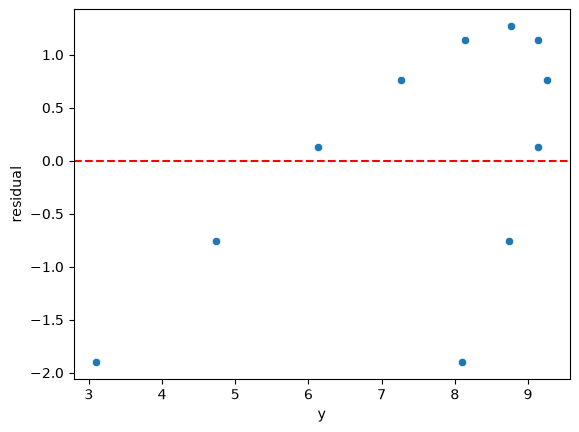

In [20]:
sns.scatterplot(data=quartet2,x='y',y='residual')
plt.axhline(y=0, color='r', linestyle='--');

### The residual plots is not symmetric about zero interms of the number of data points also the distribution has a shape which is an indication of the need to go to a higher degree.

In [21]:
quartet3
quartet3['pred_y'] = 3 + 0.5 * quartet3['x']
quartet3['residual'] = quartet3['y'] - quartet3['pred_y']

In [22]:
quartet3

,x,y,pred_y,residual
0,8.0,6.58,7.0,-0.42
1,8.0,5.76,7.0,-1.24
2,8.0,7.71,7.0,0.71
3,8.0,8.84,7.0,1.84
4,8.0,8.47,7.0,1.47
5,8.0,7.04,7.0,0.04
6,8.0,5.25,7.0,-1.75
7,19.0,12.50,12.5,0.00
8,8.0,5.56,7.0,-1.44
9,8.0,7.91,7.0,0.91


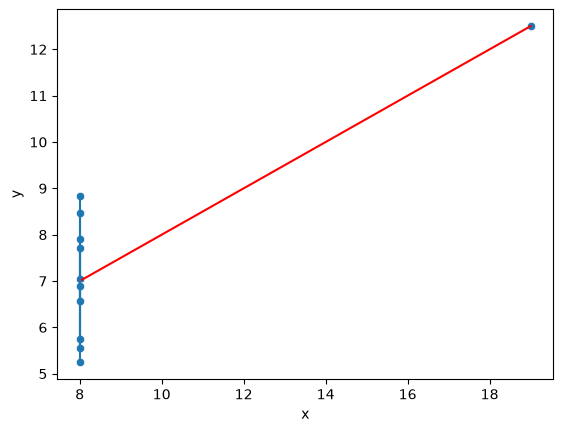

In [23]:
plt.figure()
sns.scatterplot(data=quartet3,x='x',y='y')
sns.lineplot(data=quartet3,x='x',y='pred_y',color='red')
plt.vlines(quartet3['x'],quartet3['y'],quartet3['y']-quartet3['residual'])
plt.show()

### The figure above shows data clusterd in one x value, one to many and one outlier it it clear that linear regression is not a good fit, the data needs to be one to one. 

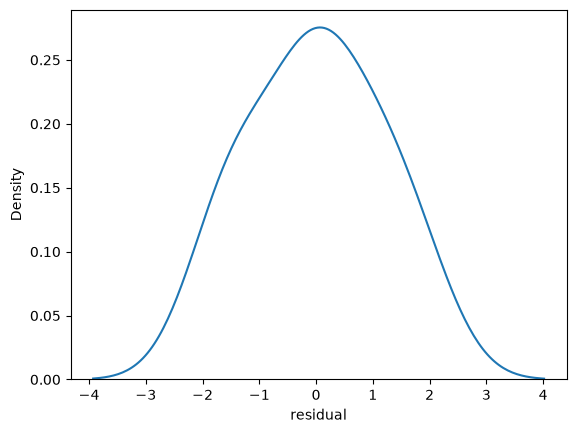

In [24]:
plt.figure()
sns.kdeplot(quartet3['residual']);

### The residual distribution is centered around zero, if we did not plot the data it would be tricky to determine if linear regression was a good fit, perhaps some kind of one to many check would suffice to note linear regression as the wrong model.
- Recall the definition of a function, it has to pass the vertical line (plate) test 
- You can have many to one functions one to many is just absurdity.

## The residual plot

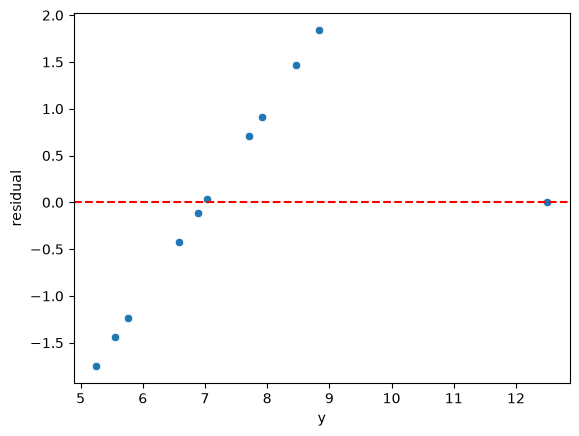

In [25]:
sns.scatterplot(data=quartet3,x='y',y='residual')
plt.axhline(y=0, color='r', linestyle='--')

## A residual plot should always be random, this one is easily predictable.

# Ploting Residuals back to our advertisement data

In [26]:
test_res = y_test - test_predictions

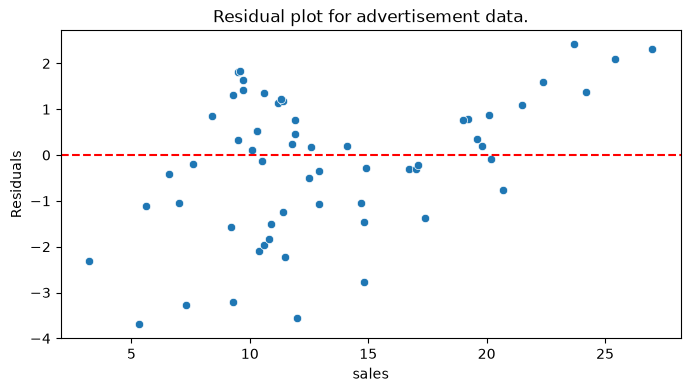

In [27]:
plt.figure(figsize=(8,4))
sns.scatterplot(x=y_test,y=test_res)
plt.axhline(y=0,color='r',linestyle='--')
plt.ylabel("Residuals")
plt.title("Residual plot for advertisement data.");

The figure above shows the residuals are randomly distributed.

In [28]:
len(test_res)

60

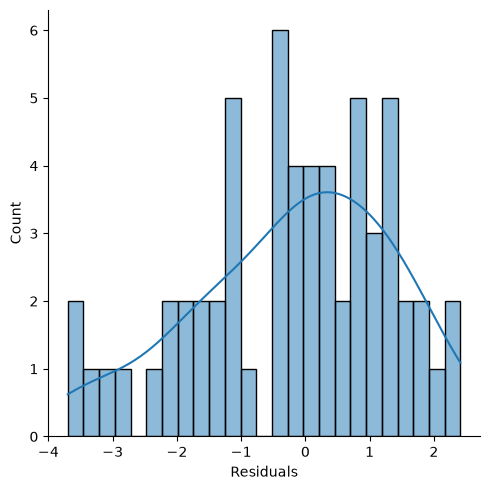

In [29]:
sns.displot(test_res,bins=25,kde=True)
plt.xlabel("Residuals");

Well the distribution plot above certainly peaks around zero, from looking it seems left skewed, then the question is how do we analyze how far a distribution is to gaussian?

## Can we truly say that the data resembles a normal distribution?
- One way to check is to use the [normal probability plot.](https://en.wikipedia.org/wiki/Normal_probability_plot).
- A normal probability plot is a graphical technique to identify substantive departures from normality, it is a check of whether the data is normally distributed.
- This includes identifying outliers, skewness, kurtosis, a need for transformations, and mixtures
- Skewness is a measure of the asymmetry of the probability distribution of a real-valued random variable about its mean.
- Kurtosis (meaning 'curved, arching') refers to the degree of tailedness in the probability distribution of a real-valued, random variable in probability theory and statistics. 

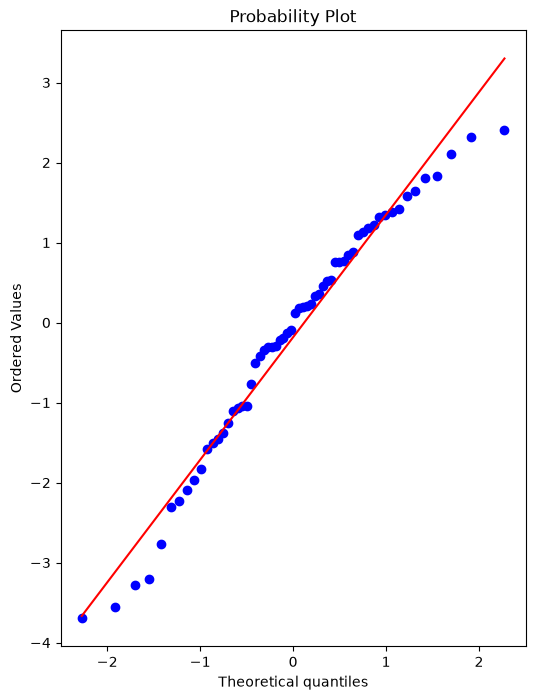

In [30]:
# Create a figure and axis to plot on
fig, ax = plt.subplots(figsize=(6,8),dpi=100)
# probplot returns the raw values if needed
# we just want to see the plot, so we assign these values to _
_ = sp.stats.probplot(test_res,plot=ax)

- This is how to interpret the above plot
  - Ideally: The blue data points should closely hug the diagonal red reference line. This confirms your residuals are normally distributed.
  - Deviations: If the points curve away from the line at the extreme ends (tails), your residuals have heavier or lighter tails than a normal distribution, which may indicate outliers or an improperly specified model.

> Well from the normal probabilty plot above it is safe to assume that linear regression works well for the advertisement data. 

 # With this bit of confidence we train the model on Full Data

In [31]:
final_model = LinearRegression()
final_model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.05, 0.19,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','radio','newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.939
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


- The metrics are important when testing the model on data it has never seen before, that is preddictive accuracy.
  - This is to say training error (calculating RMSE on seen data) only tells you **how well the model memorized its instructions** , whereas the test error is the only metric that proves true predictive capability.

# Deployment, Predictions and Model Attributes
### Let me tell you something about the data, get the budget in order.
The data is collected from 200 different markets, in each market there were budgets for TV Spend, Radio Spend and Newspaper spend. And for each market the sales value was collected. 

In [33]:
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


- We have three features that can be added to get sales
$$ sales = \beta_0 \beta X_{radio} + \beta X_{newspaper} + \beta_{TV} + \epsilon$$
  - One thing I just want to note is if you plot the sales vs each feature the order of the sales values change, like the distribution of sales changes according to the order of the values for each feature, the market position is changed according to how the feature increases.
  - It happens that for one feature you will get the sales increasing with an increase in the feature. 
  - For another you may find that as the feature value increases the sales value does not show an increase or a decrease, it just appears random.
  - This indicates in itself that the feature might as well be left out and the money for that feature be spent on the features which show an actuall increase as they go up.

- Random feature.
  - Consider two features that show that as they are increased the sales value increases. 
  - Then one feature that appears to not sure an obvious increase or decrease simply random.
  - When linear regression is used for the three features the first 2 cefficients of the model will be positive to indicate the increasing features and the 3rd very close to zero to show little contribution to the final sales value.

> These coefficients can then be used to predict future sales.

In [34]:
y_hat = final_model.predict(X)

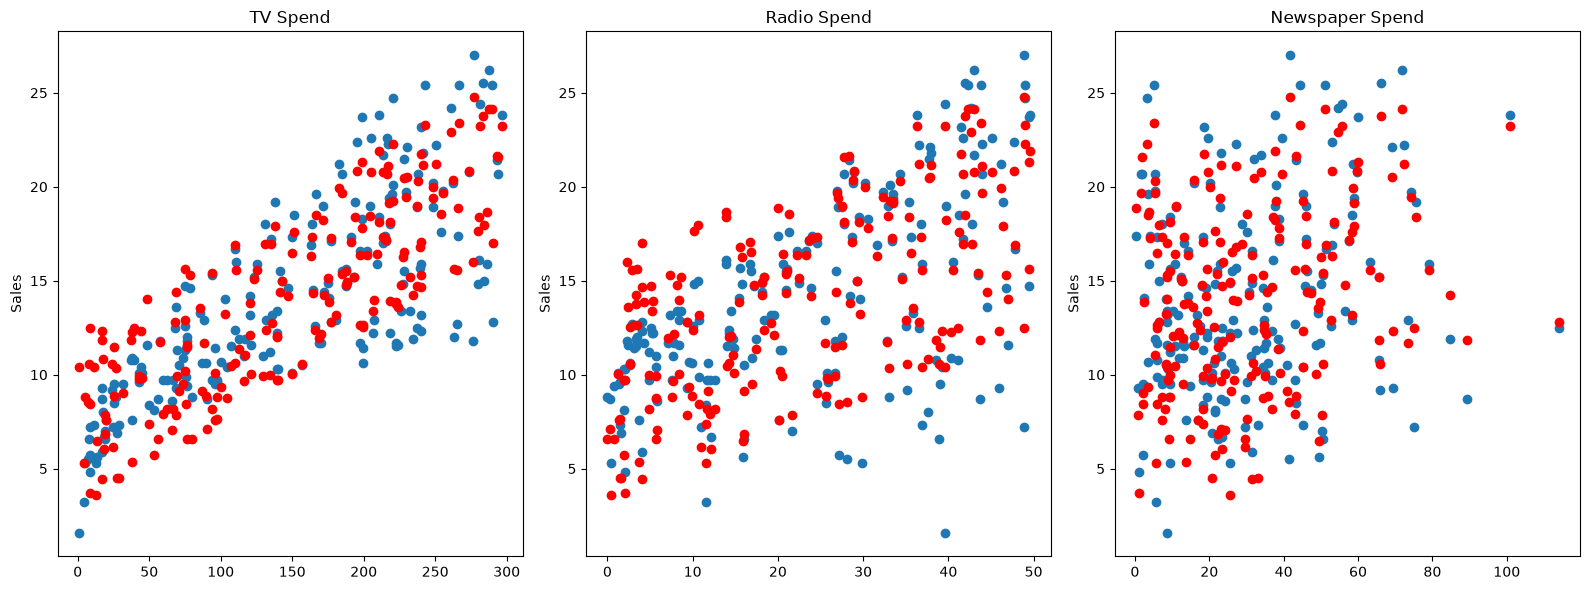

In [37]:
fig,axes = plt.subplots(nrows=1,ncols=3,figsize=(16,6))

axes[0].plot(df['TV'],df['sales'],'o')
axes[0].plot(df['TV'],y_hat,'o',color='red')
axes[0].set_ylabel("Sales")
axes[0].set_title("TV Spend")

axes[1].plot(df['radio'],df['sales'],'o')
axes[1].plot(df['radio'],y_hat,'o',color='red')
axes[1].set_title("Radio Spend")
axes[1].set_ylabel("Sales")

axes[2].plot(df['newspaper'],df['sales'],'o')
axes[2].plot(df['newspaper'],y_hat,'o',color='red')
axes[2].set_title("Newspaper Spend");
axes[2].set_ylabel("Sales")
plt.tight_layout();

## Residuals

In [39]:
residuals =  y_hat - y
residuals

0     -1.576026
1      1.937855
2      3.007671
3     -0.902170
4      0.288672
         ...   
195   -2.229658
196   -1.534688
197   -0.014079
198   -1.732679
199    1.773196
Name: sales, Length: 200, dtype: float64

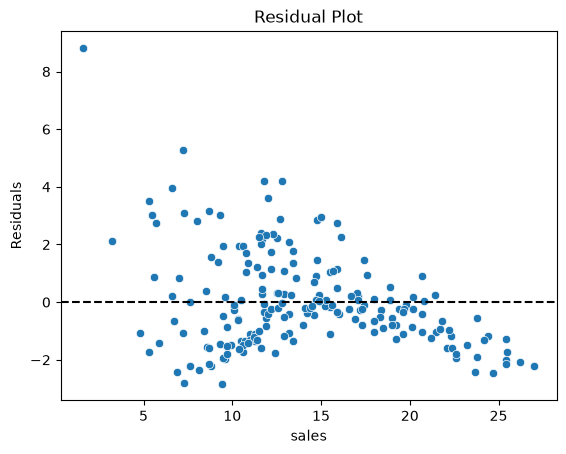

In [44]:
sns.scatterplot(x=y,y=residuals)
plt.axhline(y=0,color='black',linestyle='--')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

The residual plot shows that the residuals are random, which is a good indication that linear regression is a good fit

## Coefficients

In [ ]:
coeff_df = pd.DataFrame(final_model.coef_,X.columns,columns=['Coefficient'])
coeff_df

,Coefficient
TV,0.045765
radio,0.188530
newspaper,-0.001037


Interpreting the coefficients:
> TV spend
---
* Holding all other features fixed, a 1 unit (A thousand dollars) increase in TV Spend is associated with an increase in sales of  0.045 "sales units", in this case 1000s of units . 
* This basically means that for every $1000 dollars spend on TV Ads, we could expect 45 more units sold.
----
> Radio spend
----
* Holding all other features fixed, a 1 unit (A thousand dollars) increase in Radio Spend is associated with an increase in sales of  0.188 "sales units", in this case 1000s of units . 
* This basically means that for every $1000 dollars spend on Radio Ads, we could expect 188 more units sold.
----
> Newspaper spend
* Holding all other features fixed, a 1 unit (A thousand dollars) increase in Newspaper Spend is associated with a **decrease** in sales of  0.001 "sales units", in this case 1000s of units . 
* This basically means that for every $1000 dollars spend on Newspaper Ads, we could actually expect to sell 1 less unit. Being so close to 0, this heavily implies that newspaper spend has no real effect on sales.
---

In [48]:
df.corr()

,TV,radio,newspaper,sales
TV,1.000000,0.054809,0.056648,0.782224
radio,0.054809,1.000000,0.354104,0.576223
newspaper,0.056648,0.354104,1.000000,0.228299
sales,0.782224,0.576223,0.228299,1.000000


## Prediction on New Data

**Our next ad campaign will have a total spend of 149k on TV, 22k on Radio, and 12k on Newspaper Ads, how many units could we expect to sell as a result of this?**

In [50]:
campaign = [[149,22,12]]
final_model.predict(campaign)

c:\Users\moele\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([13.893032])

How accurate is this prediction? No real way to know! We only know truly know our model's performance on the test data, that is why we had to be satisfied by it first, before training our full model

## Model Persistence (Saving and Loading a Model)

In [52]:
from joblib import dump, load

In [53]:
sales_model = r"G:\My Drive\INTRO TO ML AND DATA SCIENCE\models\lin_regression\sales_model.joblib"

dump(final_model, sales_model)

['G:\\My Drive\\INTRO TO ML AND DATA SCIENCE\\models\\lin_regression\\sales_model.joblib']

In [54]:
loaded_model = load(sales_model)

In [55]:
loaded_model.predict(campaign)

c:\Users\moele\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([13.893032])